<a href="https://colab.research.google.com/github/20deepak28/Customer-Lifetime-Value-Churn-Intelligence/blob/main/07_customer_lifetime_value_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install lifetimes openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 584.2/584.2 kB 7.4 MB/s  0:00:00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

project_path = '/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence'

data_path = os.path.join(project_path, 'data')

os.makedirs(data_path, exist_ok=True)

print("CLV notebook initialized successfully!")

CLV notebook initialized successfully!


### Download Online Retail

We'll use the official UCI dataset containing approximately 1.07 million transactions from December 2009 to December 2011. It includes customer IDs, invoice dates, quantities and unit prices.

In [3]:
import urllib.request

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00502/online_retail_II.xlsx"

file_path = os.path.join(data_path, "online_retail_II.xlsx")

if not os.path.exists(file_path):
    urllib.request.urlretrieve(url, file_path)

print("Dataset downloaded:", os.path.exists(file_path))
print("File size (MB):", round(os.path.getsize(file_path) / (1024**2), 2))

Dataset downloaded: True
File size (MB): 43.51


### LOad Both Excel Sheets

In [4]:
# Load both sheets
sheets = pd.read_excel(file_path, sheet_name=None)

print("Available sheets:", list(sheets.keys()))

# Inspect sheet dimensions
for sheet_name, data in sheets.items():
    print(f"{sheet_name}: {data.shape}")

Available sheets: ['Year 2009-2010', 'Year 2010-2011']
Year 2009-2010: (525461, 8)
Year 2010-2011: (541910, 8)


### Combine both sheets

In [5]:
# Combine both sheets
df_clv = pd.concat(
    sheets.values(),
    ignore_index=True
)

print("Combined shape:", df_clv.shape)
print("\nColumn names:")
print(df_clv.columns.tolist())

df_clv.head()

Combined shape: (1067371, 8)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


### Data Quality Assesment

In [6]:
# Check missing values
print("Missing values:")
print(df_clv.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df_clv.duplicated().sum())

# Check cancelled invoices
print("\nCancelled invoices:",
      df_clv['Invoice'].astype(str).str.startswith('C').sum())

# Check negative quantities
print("\nNegative quantities:",
      (df_clv['Quantity'] < 0).sum())

# Check zero or negative prices
print("\nInvalid prices:",
      (df_clv['Price'] <= 0).sum())

Missing values:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Duplicate rows: 34335

Cancelled invoices: 19494

Negative quantities: 22950

Invalid prices: 6207


### Data Cleaning

In [7]:
# Make a copy
df_clean = df_clv.copy()

# 1. Remove duplicate records
df_clean = df_clean.drop_duplicates()

# 2. Remove missing Customer IDs
df_clean = df_clean.dropna(subset=['Customer ID'])

# 3. Remove cancelled invoices
df_clean = df_clean[
    ~df_clean['Invoice'].astype(str).str.startswith('C')
]

# 4. Remove negative or zero quantities
df_clean = df_clean[df_clean['Quantity'] > 0]

# 5. Remove zero or negative prices
df_clean = df_clean[df_clean['Price'] > 0]

# 6. Calculate transaction revenue
df_clean['Revenue'] = (
    df_clean['Quantity'] * df_clean['Price']
)

print("Original records:", len(df_clv))
print("Cleaned records:", len(df_clean))
print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Remaining duplicates:", df_clean.duplicated().sum())

df_clean.head()

Original records: 1067371
Cleaned records: 779425
Remaining missing values: 0
Remaining duplicates: 0


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


### Customer-Level aggregation

In [8]:
# Ensure InvoiceDate is datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# Define analysis date
analysis_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

# Customer-level aggregation
customer_df = df_clean.groupby('Customer ID').agg(
    FirstPurchase=('InvoiceDate', 'min'),
    LastPurchase=('InvoiceDate', 'max'),
    Frequency=('Invoice', 'nunique'),
    TotalRevenue=('Revenue', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    AverageOrderValue=('Revenue', 'sum')
).reset_index()

# Calculate recency and customer lifespan
customer_df['Recency'] = (
    customer_df['LastPurchase'] - customer_df['FirstPurchase']
).dt.days

customer_df['CustomerLifespan'] = (
    analysis_date - customer_df['FirstPurchase']
).dt.days

# Calculate average order value correctly
customer_df['AverageOrderValue'] = (
    customer_df['TotalRevenue'] / customer_df['Frequency']
)

# Calculate average revenue per day
customer_df['AverageRevenuePerDay'] = (
    customer_df['TotalRevenue'] /
    customer_df['CustomerLifespan'].clip(lower=1)
)

customer_df.head()

,Customer ID,FirstPurchase,LastPurchase,Frequency,TotalRevenue,TotalQuantity,AverageOrderValue,Recency,CustomerLifespan,AverageRevenuePerDay
0,12346.0,2009-12-14 08:34:00,2011-01-18 10:01:00,12,77556.46,74285,6463.038333,400,726,106.827080
1,12347.0,2010-10-31 14:20:00,2011-12-07 15:52:00,8,4921.53,2967,615.191250,402,404,12.182005
2,12348.0,2010-09-27 14:59:00,2011-09-25 13:13:00,5,2019.40,2714,403.880000,362,438,4.610502
3,12349.0,2010-04-29 13:20:00,2011-11-21 09:51:00,4,4428.69,1624,1107.172500,570,589,7.518998
4,12350.0,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,334.400000,0,310,1.078710


### Undertand customer distribution

In [9]:
# Customer-level dataset overview
print("Total unique customers:", customer_df['Customer ID'].nunique())

print("\nStatistical summary:")
display(
    customer_df[
        ['Frequency', 'TotalRevenue', 'TotalQuantity',
         'AverageOrderValue', 'Recency', 'CustomerLifespan']
    ].describe().round(2)
)

Total unique customers: 5878

Statistical summary:


,Frequency,TotalRevenue,TotalQuantity,AverageOrderValue,Recency,CustomerLifespan
count,5878.00,5878.00,5878.0,5878.00,5878.00,5878.00
mean,6.29,2955.90,1788.7,385.18,273.02,474.71
std,13.01,14440.85,8876.3,1214.29,258.81,223.10
min,1.00,2.95,1.0,2.95,0.00,1.00
25%,1.00,342.28,187.0,176.68,0.00,313.00
50%,3.00,867.74,480.0,279.24,220.50,530.00
75%,7.00,2248.30,1350.0,414.90,511.00,668.00
max,398.00,580987.04,367193.0,84236.25,738.00,739.00


### Understand high-value outliers

In [10]:
# Top 10 customers by historical revenue
top_customers = customer_df.sort_values(
    by='TotalRevenue',
    ascending=False
).head(10)

display(top_customers[
    ['Customer ID', 'Frequency', 'TotalRevenue',
     'AverageOrderValue', 'Recency']
])

,Customer ID,Frequency,TotalRevenue,AverageOrderValue,Recency
5692,18102.0,145,580987.04,4006.807172,738
2277,14646.0,151,528602.52,3500.678940,735
1789,14156.0,156,313437.62,2009.215513,728
2538,14911.0,398,291420.81,732.213090,737
5050,17450.0,51,244784.25,4799.691176,429
1331,13694.0,143,195640.69,1368.116713,731
5109,17511.0,60,172132.87,2868.881167,734
4061,16446.0,2,168472.50,84236.250000,204
4295,16684.0,55,147142.77,2675.323091,728
68,12415.0,28,144458.37,5159.227500,503


### Display top 10 customers

In [11]:
top_customers = customer_df.nlargest(10, 'TotalRevenue')

display(
    top_customers[
        [
            'Customer ID',
            'Frequency',
            'TotalRevenue',
            'AverageOrderValue',
            'Recency',
            'CustomerLifespan'
        ]
    ].round(2).to_string(index=False)
)

' Customer ID  Frequency  TotalRevenue  AverageOrderValue  Recency  CustomerLifespan\n     18102.0        145     580987.04            4006.81      738               739\n     14646.0        151     528602.52            3500.68      735               737\n     14156.0        156     313437.62            2009.22      728               739\n     14911.0        398     291420.81             732.21      737               739\n     17450.0         51     244784.25            4799.69      429               438\n     13694.0        143     195640.69            1368.12      731               735\n     17511.0         60     172132.87            2868.88      734               738\n     16446.0          2     168472.50           84236.25      204               206\n     16684.0         55     147142.77            2675.32      728               732\n     12415.0         28     144458.37            5159.23      503               528'

### Customer level dataset size

In [12]:
print("Unique customers:", customer_df['Customer ID'].nunique())
print("Average customer revenue:", round(customer_df['TotalRevenue'].mean(), 2))
print("Median customer revenue:", round(customer_df['TotalRevenue'].median(), 2))
print("Maximum customer revenue:", round(customer_df['TotalRevenue'].max(), 2))

Unique customers: 5878
Average customer revenue: 2955.9
Median customer revenue: 867.74
Maximum customer revenue: 580987.04


### Revenue Distribution

In [13]:
# Revenue distribution percentiles
percentiles = customer_df['TotalRevenue'].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Customer Revenue Percentiles:")
display(percentiles)

# Total revenue concentration
total_revenue = customer_df['TotalRevenue'].sum()

top_10_percent_count = int(len(customer_df) * 0.10)

top_customers = customer_df.nlargest(
    top_10_percent_count,
    'TotalRevenue'
)

top_10_revenue_share = (
    top_customers['TotalRevenue'].sum() / total_revenue
) * 100

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Top 10% Customer Revenue Share: {top_10_revenue_share:.2f}%")

Customer Revenue Percentiles:


,TotalRevenue
0.25,342.280
0.50,867.740
0.75,2248.305
0.90,5465.741
0.95,9374.227
0.99,29205.901


Total Revenue: £17,374,804.27
Top 10% Customer Revenue Share: 63.90%


## RFM customer segmentation
We'll segment customers using:
- R — Recency: How recently they purchased.
- F — Frequency: How often they purchased.
- M — Monetary: How much they spent.

In [14]:
# Calculate RFM metrics
rfm = customer_df[
    ['Customer ID', 'LastPurchase', 'Frequency', 'TotalRevenue']
].copy()

# Reference date
analysis_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

# Recency in days
rfm['Recency'] = (
    analysis_date - rfm['LastPurchase']
).dt.days

# Rename monetary column
rfm.rename(
    columns={'TotalRevenue': 'Monetary'},
    inplace=True
)

# Create RFM scores (1 to 5)
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
rfm['RFM_Score'] = (
    rfm['R_Score'] +
    rfm['F_Score'] +
    rfm['M_Score']
)

display(rfm.head(10))

,Customer ID,LastPurchase,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,2011-01-18 10:01:00,12,77556.46,326,2,5,5,12
1,12347.0,2011-12-07 15:52:00,8,4921.53,2,5,4,5,14
2,12348.0,2011-09-25 13:13:00,5,2019.40,75,3,4,4,11
3,12349.0,2011-11-21 09:51:00,4,4428.69,19,5,3,5,13
4,12350.0,2011-02-02 16:01:00,1,334.40,310,2,1,2,5
5,12351.0,2010-11-29 15:23:00,1,300.93,375,2,1,2,5
6,12352.0,2011-11-03 14:37:00,10,2849.84,36,4,5,4,13
7,12353.0,2011-05-19 17:47:00,2,406.76,204,2,2,2,6
8,12354.0,2011-04-21 13:11:00,1,1079.40,232,2,1,3,6
9,12355.0,2011-05-09 13:49:00,2,947.61,214,2,2,3,7


### Verify RFM

In [15]:
print("RFM shape:", rfm.shape)
print("\nColumns:")
print(rfm.columns.tolist())

print("\nRFM score distributions:")

for col in ['R_Score', 'F_Score', 'M_Score']:
    print(f"\n{col}")
    print(rfm[col].value_counts().sort_index())


RFM shape: (5878, 9)

Columns:
['Customer ID', 'LastPurchase', 'Frequency', 'Monetary', 'Recency', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score']

RFM score distributions:

R_Score
R_Score
1    1176
2    1175
3    1176
4    1175
5    1176
Name: count, dtype: int64

F_Score
F_Score
1    1176
2    1175
3    1176
4    1175
5    1176
Name: count, dtype: int64

M_Score
M_Score
1    1176
2    1175
3    1176
4    1175
5    1176
Name: count, dtype: int64


### Customer segmentation

In [16]:
import numpy as np

def assign_segment(row):

    r = row['R_Score']
    f = row['F_Score']
    m = row['M_Score']

    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'

    elif r >= 3 and f >= 4:
        return 'Loyal Customers'

    elif r >= 4 and f >= 2:
        return 'Potential Loyalists'

    elif r <= 2 and f >= 3:
        return 'At Risk'

    elif r <= 2 and f <= 2:
        return 'Hibernating'

    else:
        return 'Others'


rfm['CustomerSegment'] = rfm.apply(
    assign_segment,
    axis=1
)

print(rfm['CustomerSegment'].value_counts())

display(rfm.head(10))

CustomerSegment
Hibernating            1526
Champions              1289
At Risk                 825
Others                  819
Potential Loyalists     711
Loyal Customers         708
Name: count, dtype: int64


,Customer ID,LastPurchase,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,RFM_Score,CustomerSegment
0,12346.0,2011-01-18 10:01:00,12,77556.46,326,2,5,5,12,At Risk
1,12347.0,2011-12-07 15:52:00,8,4921.53,2,5,4,5,14,Champions
2,12348.0,2011-09-25 13:13:00,5,2019.40,75,3,4,4,11,Loyal Customers
3,12349.0,2011-11-21 09:51:00,4,4428.69,19,5,3,5,13,Potential Loyalists
4,12350.0,2011-02-02 16:01:00,1,334.40,310,2,1,2,5,Hibernating
5,12351.0,2010-11-29 15:23:00,1,300.93,375,2,1,2,5,Hibernating
6,12352.0,2011-11-03 14:37:00,10,2849.84,36,4,5,4,13,Champions
7,12353.0,2011-05-19 17:47:00,2,406.76,204,2,2,2,6,Hibernating
8,12354.0,2011-04-21 13:11:00,1,1079.40,232,2,1,3,6,Hibernating
9,12355.0,2011-05-09 13:49:00,2,947.61,214,2,2,3,7,Hibernating


### Revenue contribution by segment

In [17]:
segment_analysis = rfm.groupby('CustomerSegment').agg(
    CustomerCount=('Customer ID', 'count'),
    AverageRecency=('Recency', 'mean'),
    AverageFrequency=('Frequency', 'mean'),
    AverageMonetary=('Monetary', 'mean'),
    TotalRevenue=('Monetary', 'sum')
).reset_index()

segment_analysis['RevenueShare'] = (
    segment_analysis['TotalRevenue'] /
    segment_analysis['TotalRevenue'].sum()
) * 100

segment_analysis = segment_analysis.sort_values(
    'TotalRevenue',
    ascending=False
)

display(segment_analysis.round(2))

,CustomerSegment,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary,TotalRevenue,RevenueShare
1,Champions,1289,19.72,17.15,9169.61,11819626.88,68.03
3,Loyal Customers,708,83.93,7.77,2677.45,1895631.38,10.91
0,At Risk,825,368.88,4.94,1927.74,1590384.58,9.15
5,Potential Loyalists,711,25.62,2.59,1145.29,814304.39,4.69
2,Hibernating,1526,458.75,1.25,429.52,655444.68,3.77
4,Others,819,92.79,1.87,731.88,599412.36,3.45


### Save the CLV Dataset

In [18]:
import os

data_path = os.path.join(project_path, 'data')

customer_df.to_csv(
    os.path.join(data_path, 'customer_level_clv.csv'),
    index=False
)

rfm.to_csv(
    os.path.join(data_path, 'customer_rfm_segments.csv'),
    index=False
)

segment_analysis.to_csv(
    os.path.join(data_path, 'clv_segment_analysis.csv'),
    index=False
)

print("All three datasets saved successfully!")

All three datasets saved successfully!


# **Predictive CLV model Using BG/NBD+Gamma-Gamma**

In [19]:
!pip install lifetimes

In [20]:
from lifetimes import BetaGeoFitter, GammaGammaFitter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


### Build transaction-level model inputs

In [21]:
# Prepare transaction-level data
transactions = df_clean[
    ['Customer ID', 'Invoice', 'InvoiceDate', 'Revenue']
].copy()

# Aggregate product rows into invoice-level transactions
invoice_data = transactions.groupby(
    ['Customer ID', 'Invoice', 'InvoiceDate']
).agg(
    OrderValue=('Revenue', 'sum')
).reset_index()

# Sort transactions chronologically
invoice_data = invoice_data.sort_values(
    ['Customer ID', 'InvoiceDate']
)

# Observation period end
observation_end = invoice_data['InvoiceDate'].max()

print("Unique customers:", invoice_data['Customer ID'].nunique())
print("Unique invoices:", invoice_data['Invoice'].nunique())
print("Observation end:", observation_end)

display(invoice_data.head())

Unique customers: 5878
Unique invoices: 36969
Observation end: 2011-12-09 12:50:00


,Customer ID,Invoice,InvoiceDate,OrderValue
0,12346.0,491725,2009-12-14 08:34:00,45.0
1,12346.0,491742,2009-12-14 11:00:00,22.5
2,12346.0,491744,2009-12-14 11:02:00,22.5
3,12346.0,492718,2009-12-18 10:47:00,22.5
4,12346.0,492722,2009-12-18 10:55:00,1.0


### Calculate Customer purchase behaviour

In [23]:
# Calculate BG/NBD customer metrics

summary = invoice_data.groupby('Customer ID').agg(
    Frequency=('Invoice', 'nunique'),
    FirstPurchase=('InvoiceDate', 'min'),
    LastPurchase=('InvoiceDate', 'max')
).reset_index()

# BG/NBD requires repeat purchases only
summary['Frequency'] = summary['Frequency'] - 1

# Recency: time between first and last purchase (days)
summary['Recency'] = (
    summary['LastPurchase'] - summary['FirstPurchase']
).dt.total_seconds() / 86400

# Customer age: time between first purchase and observation end
summary['T'] = (
    observation_end - summary['FirstPurchase']
).dt.total_seconds() / 86400

# Remove customers with no repeat purchases
model_data = summary[summary['Frequency'] > 0].copy()

print("Total customers:", len(summary))
print("Customers with repeat purchases:", len(model_data))
print("One-time customers:", (summary['Frequency'] == 0).sum())

display(
    model_data[
        ['Customer ID', 'Frequency', 'Recency', 'T']
    ].head(10).round(2)
)

Total customers: 5878
Customers with repeat purchases: 4255
One-time customers: 1623


,Customer ID,Frequency,Recency,T
0,12346.0,11,400.06,725.18
1,12347.0,7,402.06,403.94
2,12348.0,4,362.93,437.91
3,12349.0,3,570.85,588.98
6,12352.0,9,356.18,392.10
7,12353.0,1,204.21,408.00
9,12355.0,1,353.08,567.04
10,12356.0,5,401.96,424.13
11,12357.0,2,355.25,388.11
12,12358.0,4,730.10,731.20


### Fit the BG/NBD model

In [24]:
from lifetimes import BetaGeoFitter

# Initialize BG/NBD model
bgf = BetaGeoFitter(penalizer_coef=0.01)

# Fit model
bgf.fit(
    frequency=model_data['Frequency'],
    recency=model_data['Recency'],
    T=model_data['T']
)

print("BG/NBD model trained successfully!")

print("\nModel parameters:")
print(bgf.params_)

BG/NBD model trained successfully!

Model parameters:
r         1.245669
alpha    71.952382
a         0.086523
b         0.727649
dtype: float64


### Predict purchase over the next 90 days

In [25]:
# Predict expected purchases over the next 90 days

model_data['PredictedPurchases_90D'] = bgf.conditional_expected_number_of_purchases_up_to_time(
    90,
    model_data['Frequency'],
    model_data['Recency'],
    model_data['T']
)

print("90-day purchase predictions generated!")

display(
    model_data[
        ['Customer ID', 'Frequency', 'Recency',
         'T', 'PredictedPurchases_90D']
    ].sort_values(
        'PredictedPurchases_90D',
        ascending=False
    ).head(10).round(3)
)

90-day purchase predictions generated!


,Customer ID,Frequency,Recency,T,PredictedPurchases_90D
2538,14911.0,397,737.176,738.048,44.029
400,12748.0,335,734.784,734.805,37.326
5433,17841.0,210,735.851,736.881,23.383
2935,15311.0,207,738.027,738.062,23.021
739,13089.0,202,734.721,736.879,22.493
2237,14606.0,191,735.283,736.007,21.303
1789,14156.0,155,728.933,738.014,17.224
2277,14646.0,150,735.806,736.832,16.740
5692,18102.0,144,738.101,738.143,16.051
1331,13694.0,142,731.754,734.892,15.887


### Prepare Monetory value for Gamma-Gamma

In [26]:
# Calculate average order value for repeat customers

monetary_data = invoice_data.groupby('Customer ID').agg(
    Frequency=('Invoice', 'nunique'),
    MonetaryValue=('OrderValue', 'mean')
).reset_index()

# Keep repeat customers with positive monetary value
monetary_data = monetary_data[
    (monetary_data['Frequency'] > 1) &
    (monetary_data['MonetaryValue'] > 0)
].copy()

print("Customers for Gamma-Gamma:", len(monetary_data))

display(
    monetary_data.sort_values(
        'MonetaryValue',
        ascending=False
    ).head(10)
)

Customers for Gamma-Gamma: 4255


,Customer ID,Frequency,MonetaryValue
4061,16446.0,2,84236.250000
3371,15749.0,3,14844.766667
2722,15098.0,3,13305.500000
3382,15760.0,2,6958.170000
1538,13902.0,5,6819.052000
0,12346.0,12,6463.038333
11,12357.0,3,6095.886667
68,12415.0,28,5159.227500
243,12590.0,2,4932.130000
5050,17450.0,51,4799.691176


### TEst the Gamma-Gamma assumption

In [27]:
# Check correlation between purchase frequency and average order value

correlation = monetary_data[
    ['Frequency', 'MonetaryValue']
].corr().iloc[0, 1]

print("Frequency-Monetary correlation:", round(correlation, 4))

# Statistical summary
display(
    monetary_data[
        ['Frequency', 'MonetaryValue']
    ].describe().round(2)
)

Frequency-Monetary correlation: 0.0307


,Frequency,MonetaryValue
count,4255.00,4255.00
mean,8.31,399.75
std,14.80,1378.02
min,2.00,7.74
25%,3.00,194.18
50%,5.00,292.60
75%,9.00,426.25
max,398.00,84236.25


### Train Gamma-Gamma model

In [28]:
# Initialize Gamma-Gamma model
ggf = GammaGammaFitter(penalizer_coef=0.01)

# Fit model
ggf.fit(
    monetary_data['Frequency'],
    monetary_data['MonetaryValue']
)

print("Gamma-Gamma model trained successfully!")

print("\nModel parameters:")
print(ggf.params_)

Gamma-Gamma model trained successfully!

Model parameters:
p    3.798680
q    0.341896
v    3.741122
dtype: float64


### Calculate pedictive CLV

In [29]:
# Calculate expected average transaction value
monetary_data['ExpectedOrderValue'] = ggf.conditional_expected_average_profit(
    monetary_data['Frequency'],
    monetary_data['MonetaryValue']
)

# Merge BG/NBD predictions with monetary estimates
clv_data = model_data.merge(
    monetary_data[
        ['Customer ID', 'ExpectedOrderValue']
    ],
    on='Customer ID',
    how='inner'
)

# Calculate predicted 90-day revenue
clv_data['PredictedCLV_90D'] = (
    clv_data['PredictedPurchases_90D'] *
    clv_data['ExpectedOrderValue']
)

print("Predictive CLV calculated!")
print("Customers evaluated:", len(clv_data))

display(
    clv_data[
        [
            'Customer ID',
            'PredictedPurchases_90D',
            'ExpectedOrderValue',
            'PredictedCLV_90D'
        ]
    ].sort_values(
        'PredictedCLV_90D',
        ascending=False
    ).head(15).round(2)
)

Predictive CLV calculated!
Customers evaluated: 4255


,Customer ID,PredictedPurchases_90D,ExpectedOrderValue,PredictedCLV_90D
4139,18102.0,16.05,4011.63,64392.44
2944,16446.0,0.64,92227.08,58824.20
1652,14646.0,16.74,3504.72,58668.97
3682,17450.0,8.95,4816.12,43083.02
1290,14156.0,17.22,2011.47,34646.20
1247,14096.0,8.72,3872.91,33753.34
1840,14911.0,44.03,728.88,32092.12
949,13694.0,15.89,1369.80,21761.53
51,12415.0,4.17,5191.48,21662.97
3728,17511.0,6.66,2830.08,18844.77


### Evaluate overall predictive CLV

In [30]:
# Overall predictive CLV statistics

print("Total customers:", len(clv_data))

print(
    "Average predicted 90-day CLV:",
    round(clv_data['PredictedCLV_90D'].mean(), 2)
)

print(
    "Median predicted 90-day CLV:",
    round(clv_data['PredictedCLV_90D'].median(), 2)
)

print(
    "Total predicted 90-day revenue:",
    round(clv_data['PredictedCLV_90D'].sum(), 2)
)

print("\nCLV distribution:")

display(
    clv_data['PredictedCLV_90D']
    .describe(percentiles=[.25, .50, .75, .90, .95, .99])
    .round(2)
)

Total customers: 4255
Average predicted 90-day CLV: 550.48
Median predicted 90-day CLV: 222.85
Total predicted 90-day revenue: 2342277.0

CLV distribution:


,PredictedCLV_90D
count,4255.00
mean,550.48
std,2212.68
min,0.00
25%,84.58
50%,222.85
75%,512.94
90%,1009.81
95%,1556.34
99%,4526.54


### Connect CLV with RFM segments

In [31]:
# Merge RFM segments with predictive CLV

clv_segmented = clv_data.merge(
    rfm[['Customer ID', 'CustomerSegment', 'RFM_Score']],
    on='Customer ID',
    how='left'
)

# Segment-level predictive CLV analysis

predictive_segment_analysis = clv_segmented.groupby(
    'CustomerSegment'
).agg(
    CustomerCount=('Customer ID', 'count'),
    AveragePredictedCLV=('PredictedCLV_90D', 'mean'),
    MedianPredictedCLV=('PredictedCLV_90D', 'median'),
    TotalPredictedRevenue=('PredictedCLV_90D', 'sum')
).reset_index()

predictive_segment_analysis = predictive_segment_analysis.sort_values(
    'TotalPredictedRevenue',
    ascending=False
)

display(predictive_segment_analysis.round(2))

,CustomerSegment,CustomerCount,AveragePredictedCLV,MedianPredictedCLV,TotalPredictedRevenue
1,Champions,1289,1241.64,597.66,1600469.97
5,Potential Loyalists,640,478.75,223.41,306399.29
3,Loyal Customers,708,354.94,247.41,251299.93
4,Others,407,205.14,149.56,83490.46
0,At Risk,825,98.99,58.02,81663.85
2,Hibernating,386,49.10,30.56,18953.50


### Retention priority matrix

In [32]:
# Create retention priority categories

clv_segmented['RetentionPriority'] = np.select(
    [
        (clv_segmented['CustomerSegment'] == 'At Risk') &
        (clv_segmented['PredictedCLV_90D'] >= 500),

        (clv_segmented['CustomerSegment'] == 'At Risk') &
        (clv_segmented['PredictedCLV_90D'] < 500),

        (clv_segmented['CustomerSegment'] == 'Champions'),

        (clv_segmented['CustomerSegment'] == 'Potential Loyalists')
    ],
    [
        'High Priority - At Risk',
        'Medium Priority - At Risk',
        'Protect Champions',
        'Growth Opportunity'
    ],
    default='Standard Monitoring'
)

# Analyse retention priorities

priority_analysis = clv_segmented.groupby(
    'RetentionPriority'
).agg(
    CustomerCount=('Customer ID', 'count'),
    AverageCLV=('PredictedCLV_90D', 'mean'),
    TotalCLV=('PredictedCLV_90D', 'sum')
).reset_index()

display(priority_analysis.round(2))

,RetentionPriority,CustomerCount,AverageCLV,TotalCLV
0,Growth Opportunity,640,478.75,306399.29
1,High Priority - At Risk,10,1374.14,13741.42
2,Medium Priority - At Risk,815,83.34,67922.43
3,Protect Champions,1289,1241.64,1600469.97
4,Standard Monitoring,1501,235.67,353743.88


### VAlidate the predictive CLV model

In [34]:
# Define a 90-day validation period

validation_end = invoice_data['InvoiceDate'].max()
calibration_end = validation_end - pd.Timedelta(days=90)

calibration_end, validation_end


(Timestamp('2011-09-10 12:50:00'), Timestamp('2011-12-09 12:50:00'))

## Split historical and future transaction

In [35]:
# Split transactions into calibration and validation periods

calibration_data = invoice_data[
    invoice_data['InvoiceDate'] <= calibration_end
].copy()

validation_data = invoice_data[
    invoice_data['InvoiceDate'] > calibration_end
].copy()

print("Calibration transactions:", len(calibration_data))
print("Validation transactions:", len(validation_data))

print("\nCalibration period:")
print(calibration_data['InvoiceDate'].min(), "to",
      calibration_data['InvoiceDate'].max())

print("\nValidation period:")
print(validation_data['InvoiceDate'].min(), "to",
      validation_data['InvoiceDate'].max())

Calibration transactions: 30403
Validation transactions: 6630

Calibration period:
2009-12-01 07:45:00 to 2011-09-09 15:53:00

Validation period:
2011-09-11 10:35:00 to 2011-12-09 12:50:00


### Build calibration customer summary

In [36]:
# Customer summary using calibration data only

calibration_end_date = calibration_data['InvoiceDate'].max()

calibration_summary = calibration_data.groupby('Customer ID').agg(
    Frequency=('Invoice', 'nunique'),
    FirstPurchase=('InvoiceDate', 'min'),
    LastPurchase=('InvoiceDate', 'max')
).reset_index()

calibration_summary['Frequency'] -= 1

calibration_summary['Recency'] = (
    calibration_summary['LastPurchase'] -
    calibration_summary['FirstPurchase']
).dt.total_seconds() / 86400

calibration_summary['T'] = (
    calibration_end_date -
    calibration_summary['FirstPurchase']
).dt.total_seconds() / 86400

calibration_model_data = calibration_summary[
    calibration_summary['Frequency'] > 0
].copy()

print("Total calibration customers:", len(calibration_summary))
print("Repeat customers:", len(calibration_model_data))
print("One-time customers:",
      len(calibration_summary) - len(calibration_model_data))

display(calibration_model_data.head())

Total calibration customers: 5281
Repeat customers: 3705
One-time customers: 1576


,Customer ID,Frequency,FirstPurchase,LastPurchase,Recency,T
0,12346.0,11,2009-12-14 08:34:00,2011-01-18 10:01:00,400.060417,634.304861
1,12347.0,5,2010-10-31 14:20:00,2011-08-02 08:48:00,274.769444,313.064583
2,12348.0,3,2010-09-27 14:59:00,2011-04-05 10:47:00,189.825000,347.037500
3,12349.0,2,2010-04-29 13:20:00,2010-10-28 08:23:00,181.793750,498.106250
6,12352.0,6,2010-11-12 10:20:00,2011-03-22 16:08:00,130.241667,301.231250


## Fit BG/NBD on calibration data

In [37]:
from lifetimes import BetaGeoFitter

# Train BG/NBD using calibration data only

bgf_validation = BetaGeoFitter(penalizer_coef=0.01)

bgf_validation.fit(
    calibration_model_data['Frequency'],
    calibration_model_data['Recency'],
    calibration_model_data['T']
)

print("BG/NBD calibration model fitted successfully!")
print(bgf_validation.summary)

BG/NBD calibration model fitted successfully!
            coef  se(coef)  lower 95% bound  upper 95% bound
r       1.311960  0.033758         1.245795         1.378125
alpha  72.755581  2.295805        68.255803        77.255359
a       0.138860  0.009015         0.121191         0.156530
b       0.828146  0.059917         0.710708         0.945584


### Predict purchase for the next 90 days

In [38]:
# Predict expected purchases over the next 90 days

calibration_model_data['PredictedPurchases_90D'] = (
    bgf_validation.conditional_expected_number_of_purchases_up_to_time(
        90,
        calibration_model_data['Frequency'],
        calibration_model_data['Recency'],
        calibration_model_data['T']
    )
)

print("Total predicted purchases:",
      round(calibration_model_data['PredictedPurchases_90D'].sum(), 2))

display(
    calibration_model_data[
        ['Customer ID', 'Frequency', 'Recency',
         'PredictedPurchases_90D']
    ].head(10)
)

Total predicted purchases: 3891.23


,Customer ID,Frequency,Recency,PredictedPurchases_90D
0,12346.0,11,400.060417,0.550829
1,12347.0,5,274.769444,1.369664
2,12348.0,3,189.825000,0.661919
3,12349.0,2,181.793750,0.244716
6,12352.0,6,130.241667,0.561564
7,12353.0,1,204.210417,0.380279
9,12355.0,1,353.076389,0.286105
10,12356.0,4,179.118750,0.793131
11,12357.0,1,0.183333,0.067177
12,12358.0,3,581.086806,0.502345


### Calculate Actual purchase

In [39]:
# Count actual purchases during the validation period

actual_purchases = validation_data.groupby('Customer ID').agg(
    ActualPurchases_90D=('Invoice', 'nunique')
).reset_index()

print("Customers who purchased during validation:",
      len(actual_purchases))

print("Total actual purchases:",
      actual_purchases['ActualPurchases_90D'].sum())

display(actual_purchases.head(10))

Customers who purchased during validation: 2889
Total actual purchases: 6626


,Customer ID,ActualPurchases_90D
0,12347.0,2
1,12348.0,1
2,12349.0,1
3,12352.0,3
4,12356.0,1
5,12357.0,1
6,12358.0,1
7,12359.0,1
8,12360.0,1
9,12362.0,6


### Predicted VS Actual purchases

In [40]:
# Merge predicted and actual purchases

validation_comparison = calibration_model_data[
    ['Customer ID', 'PredictedPurchases_90D']
].merge(
    actual_purchases,
    on='Customer ID',
    how='left'
)

validation_comparison['ActualPurchases_90D'] = (
    validation_comparison['ActualPurchases_90D'].fillna(0)
)

# Calculate aggregate performance

total_predicted = validation_comparison['PredictedPurchases_90D'].sum()
total_actual = validation_comparison['ActualPurchases_90D'].sum()

absolute_error = abs(total_actual - total_predicted)
percentage_error = (absolute_error / total_actual) * 100

print("Customers evaluated:", len(validation_comparison))
print("Predicted purchases:", round(total_predicted, 2))
print("Actual purchases:", int(total_actual))
print("Absolute error:", round(absolute_error, 2))
print("Aggregate percentage error:", round(percentage_error, 2), "%")

Customers evaluated: 3705
Predicted purchases: 3891.23
Actual purchases: 5081
Absolute error: 1189.77
Aggregate percentage error: 23.42 %


### Calculate additional validation metrics

In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_true = validation_comparison['ActualPurchases_90D']
y_pred = validation_comparison['PredictedPurchases_90D']

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
bias = (y_pred - y_true).mean()

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("Mean Forecast Bias:", round(bias, 4))

Mean Absolute Error (MAE): 0.9465
Root Mean Squared Error (RMSE): 1.9117
Mean Forecast Bias: -0.3211


### Visualize

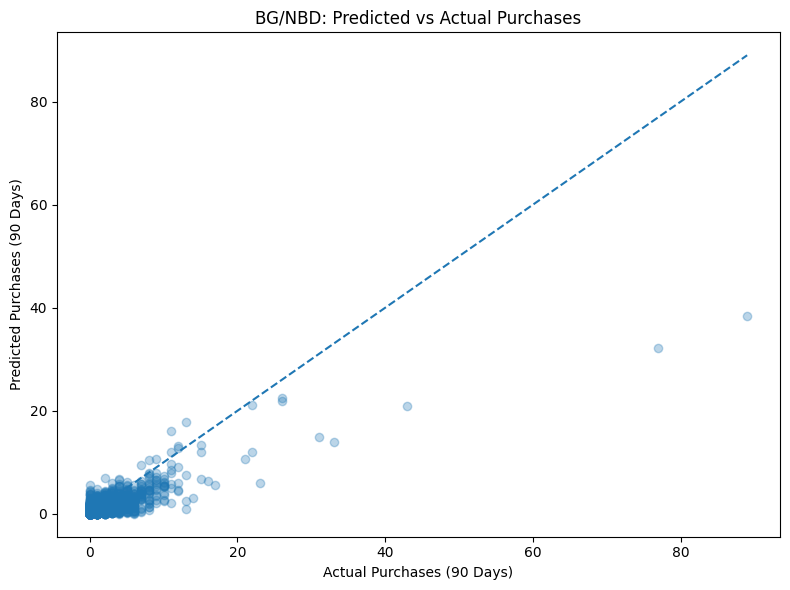

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    validation_comparison['ActualPurchases_90D'],
    validation_comparison['PredictedPurchases_90D'],
    alpha=0.3
)

max_value = max(
    validation_comparison['ActualPurchases_90D'].max(),
    validation_comparison['PredictedPurchases_90D'].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle='--'
)

plt.xlabel("Actual Purchases (90 Days)")
plt.ylabel("Predicted Purchases (90 Days)")
plt.title("BG/NBD: Predicted vs Actual Purchases")
plt.tight_layout()
plt.show()

### Customer level prediction analysis

In [43]:
# Divide customers into 5 groups based on predicted purchases

validation_comparison['PredictionGroup'] = pd.qcut(
    validation_comparison['PredictedPurchases_90D'].rank(
        method='first'
    ),
    q=5,
    labels=[
        'Very Low',
        'Low',
        'Medium',
        'High',
        'Very High'
    ]
)

# Compare predicted and actual purchases

group_analysis = validation_comparison.groupby(
    'PredictionGroup',
    observed=True
).agg(
    CustomerCount=('Customer ID', 'count'),
    AveragePredicted=('PredictedPurchases_90D', 'mean'),
    AverageActual=('ActualPurchases_90D', 'mean')
).reset_index()

group_analysis['ForecastError'] = (
    group_analysis['AveragePredicted'] -
    group_analysis['AverageActual']
)

display(group_analysis.round(3))

,PredictionGroup,CustomerCount,AveragePredicted,AverageActual,ForecastError
0,Very Low,741,0.100,0.323,-0.223
1,Low,741,0.334,0.526,-0.193
2,Medium,741,0.644,0.841,-0.197
3,High,741,1.114,1.367,-0.253
4,Very High,741,3.060,3.800,-0.741


### Check prediction-group calculations

In [44]:
group_analysis['CalculatedError'] = (
    group_analysis['AveragePredicted'] -
    group_analysis['AverageActual']
)

display(group_analysis.round(4))

,PredictionGroup,CustomerCount,AveragePredicted,AverageActual,ForecastError,CalculatedError
0,Very Low,741,0.0995,0.3225,-0.2230,-0.2230
1,Low,741,0.3337,0.5263,-0.1927,-0.1927
2,Medium,741,0.6442,0.8408,-0.1966,-0.1966
3,High,741,1.1144,1.3671,-0.2527,-0.2527
4,Very High,741,3.0596,3.8003,-0.7407,-0.7407


### Quantity the error by group

In [45]:
group_totals = validation_comparison.groupby(
    'PredictionGroup',
    observed=True
).agg(
    PredictedPurchases=('PredictedPurchases_90D', 'sum'),
    ActualPurchases=('ActualPurchases_90D', 'sum')
).reset_index()

group_totals['AbsoluteError'] = abs(
    group_totals['ActualPurchases'] -
    group_totals['PredictedPurchases']
)

group_totals['UnderpredictionPercent'] = (
    group_totals['AbsoluteError'] /
    group_totals['ActualPurchases'].replace(0, np.nan)
) * 100

display(group_totals.round(2))

,PredictionGroup,PredictedPurchases,ActualPurchases,AbsoluteError,UnderpredictionPercent
0,Very Low,73.75,239.0,165.25,69.14
1,Low,247.24,390.0,142.76,36.60
2,Medium,477.32,623.0,145.68,23.38
3,High,825.74,1013.0,187.26,18.49
4,Very High,2267.17,2816.0,548.83,19.49


### Investigate high-frequency customers

In [46]:
# Identify customers with the largest actual purchase counts

top_actual_customers = validation_comparison.sort_values(
    'ActualPurchases_90D',
    ascending=False
).head(15)

top_actual_customers = top_actual_customers[
    [
        'Customer ID',
        'PredictedPurchases_90D',
        'ActualPurchases_90D'
    ]
].copy()

top_actual_customers['PredictionError'] = (
    top_actual_customers['PredictedPurchases_90D'] -
    top_actual_customers['ActualPurchases_90D']
)

display(top_actual_customers.round(2))

,Customer ID,PredictedPurchases_90D,ActualPurchases_90D,PredictionError
1589,14911.0,38.30,89.0,-50.70
237,12748.0,32.27,77.0,-44.73
3451,17841.0,20.88,43.0,-22.12
3606,18102.0,13.87,33.0,-19.13
1422,14646.0,14.92,31.0,-16.08
1843,15311.0,22.56,26.0,-3.44
439,13089.0,21.88,26.0,-4.12
3206,17450.0,5.94,23.0,-17.06
363,12971.0,11.91,22.0,-10.09
1397,14606.0,21.14,22.0,-0.86


### Measure how concentrated the error is

In [47]:
# Calculate customer-level underprediction

validation_comparison['Underprediction'] = (
    validation_comparison['ActualPurchases_90D'] -
    validation_comparison['PredictedPurchases_90D']
)

# Total underprediction across all customers

total_underprediction = (
    validation_comparison['Underprediction'].sum()
)

# Top 15 customers by actual purchases

top_15 = validation_comparison.nlargest(
    15, 'ActualPurchases_90D'
)

top_15_underprediction = top_15['Underprediction'].sum()

contribution = (
    top_15_underprediction / total_underprediction
) * 100

print("Total underprediction:",
      round(total_underprediction, 2))

print("Top 15 customer underprediction:",
      round(top_15_underprediction, 2))

print("Top 15 contribution to total underprediction:",
      round(contribution, 2), "%")

Total underprediction: 1189.77
Top 15 customer underprediction: 224.51
Top 15 contribution to total underprediction: 18.87 %


### VAlidate Gamma-Gamma Monetory predictions

In [49]:
# Rebuild calibration transactions with Revenue

calibration_data = df_clean[
    df_clean['InvoiceDate'] <= calibration_end
].copy()

# Aggregate invoice-level revenue

calibration_invoice_data = calibration_data.groupby(
    ['Customer ID', 'Invoice', 'InvoiceDate']
).agg(
    OrderValue=('Revenue', 'sum')
).reset_index()

print("Calibration invoices:", len(calibration_invoice_data))
print("Total calibration revenue:",
      round(calibration_invoice_data['OrderValue'].sum(), 2))

display(calibration_invoice_data.head())

Calibration invoices: 30403
Total calibration revenue: 13930556.02


,Customer ID,Invoice,InvoiceDate,OrderValue
0,12346.0,491725,2009-12-14 08:34:00,45.0
1,12346.0,491742,2009-12-14 11:00:00,22.5
2,12346.0,491744,2009-12-14 11:02:00,22.5
3,12346.0,492718,2009-12-18 10:47:00,22.5
4,12346.0,492722,2009-12-18 10:55:00,1.0


In [50]:
# Calculate historical customer purchasing values

calibration_monetary = calibration_invoice_data.groupby(
    'Customer ID'
).agg(
    Frequency=('Invoice', 'nunique'),
    MonetaryValue=('OrderValue', 'mean')
).reset_index()

# Gamma-Gamma requires repeat purchasers

calibration_monetary = calibration_monetary[
    (calibration_monetary['Frequency'] > 1) &
    (calibration_monetary['MonetaryValue'] > 0)
].copy()

print("Customers eligible for Gamma-Gamma:",
      len(calibration_monetary))

print("\nAverage order value:",
      round(calibration_monetary['MonetaryValue'].mean(), 2))

display(calibration_monetary.head(10))

Customers eligible for Gamma-Gamma: 3705

Average order value: 380.82


,Customer ID,Frequency,MonetaryValue
0,12346.0,12,6463.038333
1,12347.0,6,567.065000
2,12348.0,4,427.350000
3,12349.0,3,890.380000
6,12352.0,7,272.230000
7,12353.0,2,203.380000
9,12355.0,2,473.805000
10,12356.0,5,1262.676000
11,12357.0,2,6039.995000
12,12358.0,4,800.967500


### Fit Gamma-Gamma using calibration data

In [51]:
from lifetimes import GammaGammaFitter

ggf_validation = GammaGammaFitter(penalizer_coef=0.01)

ggf_validation.fit(
    calibration_monetary['Frequency'],
    calibration_monetary['MonetaryValue']
)

print("Gamma-Gamma calibration model fitted successfully!")
display(ggf_validation.summary)

Gamma-Gamma calibration model fitted successfully!


,coef,se(coef),lower 95% bound,upper 95% bound
p,3.802823,0.085260,3.635713,3.969933
q,0.342929,0.006371,0.330442,0.355416
v,3.743032,0.085686,3.575088,3.910976


### Predict expected avg order value

In [52]:
# Predict expected average order value

calibration_monetary['PredictedOrderValue'] = (
    ggf_validation.conditional_expected_average_profit(
        calibration_monetary['Frequency'],
        calibration_monetary['MonetaryValue']
    )
)

print(
    "Average predicted order value:",
    round(calibration_monetary['PredictedOrderValue'].mean(), 2)
)

display(
    calibration_monetary[
        ['Customer ID', 'Frequency',
         'MonetaryValue', 'PredictedOrderValue']
    ].head(10)
)

Average predicted order value: 399.1


,Customer ID,Frequency,MonetaryValue,PredictedOrderValue
0,12346.0,12,6463.038333,6557.774056
1,12347.0,6,567.065000,584.521609
2,12348.0,4,427.350000,447.621332
3,12349.0,3,890.380000,946.119459
6,12352.0,7,272.230000,279.667926
7,12353.0,2,203.380000,224.660510
9,12355.0,2,473.805000,520.657440
10,12356.0,5,1262.676000,1308.647566
11,12357.0,2,6039.995000,6613.197511
12,12358.0,4,800.967500,838.106329


### Calculate actual average order values

In [54]:
# Rebuild validation transactions with Revenue

validation_data = df_clean[
    df_clean['InvoiceDate'] > calibration_end
].copy()

validation_invoice_data = validation_data.groupby(
    ['Customer ID', 'Invoice', 'InvoiceDate']
).agg(
    ActualOrderValue=('Revenue', 'sum')
).reset_index()

print("Validation invoices:", len(validation_invoice_data))

print(
    "Validation revenue:",
    round(validation_invoice_data['ActualOrderValue'].sum(), 2)
)

display(validation_invoice_data.head())

Validation invoices: 6630
Validation revenue: 3444248.25


,Customer ID,Invoice,InvoiceDate,ActualOrderValue
0,12347.0,573511,2011-10-31 12:25:00,1294.32
1,12347.0,581180,2011-12-07 15:52:00,224.82
2,12348.0,568172,2011-09-25 13:13:00,310.00
3,12349.0,577609,2011-11-21 09:51:00,1757.55
4,12352.0,567505,2011-09-20 14:34:00,366.25


### Complete Gamma-Gamma Validation

In [55]:
# Calculate actual customer-level monetary values

actual_monetary = validation_invoice_data.groupby(
    'Customer ID'
).agg(
    ActualFrequency=('Invoice', 'nunique'),
    ActualMonetaryValue=('ActualOrderValue', 'mean'),
    ActualRevenue=('ActualOrderValue', 'sum')
).reset_index()

# Compare with predicted monetary values

monetary_validation = calibration_monetary[
    ['Customer ID', 'PredictedOrderValue']
].merge(
    actual_monetary,
    on='Customer ID',
    how='inner'
)

print("Customers evaluated:", len(monetary_validation))

print(
    "Average predicted order value:",
    round(monetary_validation['PredictedOrderValue'].mean(), 2)
)

print(
    "Average actual order value:",
    round(monetary_validation['ActualMonetaryValue'].mean(), 2)
)

display(monetary_validation.head(10))

Customers evaluated: 1974
Average predicted order value: 414.41
Average actual order value: 436.35


,Customer ID,PredictedOrderValue,ActualFrequency,ActualMonetaryValue,ActualRevenue
0,12347.0,584.521609,2,759.570000,1519.14
1,12348.0,447.621332,1,310.000000,310.00
2,12349.0,946.119459,1,1757.550000,1757.55
3,12352.0,279.667926,3,314.743333,944.23
4,12356.0,1308.647566,1,58.350000,58.35
5,12357.0,6613.197511,1,6207.670000,6207.67
6,12358.0,838.106329,1,683.200000,683.20
7,12359.0,686.834194,1,2814.300000,2814.30
8,12360.0,470.594976,1,1043.780000,1043.78
9,12362.0,389.684957,6,579.813333,3478.88


### Calculate Monetory prediction errors

In [56]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_true = monetary_validation['ActualMonetaryValue']
y_pred = monetary_validation['PredictedOrderValue']

mae = mean_absolute_error(y_true, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

bias = (y_pred - y_true).mean()

mape = (
    np.abs((y_true - y_pred) / y_true).mean()
) * 100

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("Mean Bias:", round(bias, 2))
print("MAPE:", round(mape, 2), "%")

MAE: 169.8
RMSE: 306.27
Mean Bias: -21.94
MAPE: 63.62 %


### Investigate monetary outliers

In [57]:
# Calculate absolute monetary prediction errors

monetary_validation['AbsoluteError'] = abs(
    monetary_validation['ActualMonetaryValue'] -
    monetary_validation['PredictedOrderValue']
)

# Identify customers with largest errors

top_monetary_errors = monetary_validation.sort_values(
    'AbsoluteError',
    ascending=False
).head(15)

display(
    top_monetary_errors[
        [
            'Customer ID',
            'PredictedOrderValue',
            'ActualMonetaryValue',
            'ActualFrequency',
            'AbsoluteError'
        ]
    ].round(2)
)

,Customer ID,PredictedOrderValue,ActualMonetaryValue,ActualFrequency,AbsoluteError
560,14096.0,87.87,4637.15,14,4549.28
7,12359.0,686.83,2814.30,1,2127.47
1314,16333.0,876.38,2751.80,4,1875.42
1871,17940.0,2031.30,192.00,1,1839.30
1690,17389.0,673.19,2481.07,9,1807.88
61,12497.0,2850.87,1043.10,1,1807.77
26,12415.0,5572.65,3804.44,6,1768.21
36,12435.0,2087.91,3850.90,1,1762.99
1156,15874.0,458.48,2198.13,1,1739.65
117,12678.0,1398.91,3115.40,3,1716.49


Some customers have extremely large prediction errors.

### Verify the largest errors

In [58]:
# Verify the largest monetary prediction errors

top_monetary_errors = monetary_validation.nlargest(
    15, 'AbsoluteError'
)

print("DataFrame columns:")
print(top_monetary_errors.columns.tolist())

display(
    top_monetary_errors[
        [
            'Customer ID',
            'PredictedOrderValue',
            'ActualMonetaryValue',
            'ActualFrequency',
            'AbsoluteError'
        ]
    ].to_string(index=False)
)

DataFrame columns:
['Customer ID', 'PredictedOrderValue', 'ActualFrequency', 'ActualMonetaryValue', 'ActualRevenue', 'AbsoluteError']


' Customer ID  PredictedOrderValue  ActualMonetaryValue  ActualFrequency  AbsoluteError\n     14096.0            87.868464          4637.150714               14    4549.282250\n     12359.0           686.834194          2814.300000                1    2127.465806\n     16333.0           876.375986          2751.800000                4    1875.424014\n     17940.0          2031.300769           192.000000                1    1839.300769\n     17389.0           673.188268          2481.066667                9    1807.878399\n     12497.0          2850.865014          1043.100000                1    1807.765014\n     12415.0          5572.651554          3804.441667                6    1768.209887\n     12435.0          2087.906431          3850.900000                1    1762.993569\n     15874.0           458.479574          2198.130000                1    1739.650426\n     12678.0          1398.913020          3115.400000                3    1716.486980\n     16126.0           872.7189

### Check whether extreme customers distort the model

In [60]:
# Calculate error concentration

total_absolute_error = monetary_validation['AbsoluteError'].sum()

top_15_error = top_monetary_errors['AbsoluteError'].sum()

error_contribution = (
    top_15_error / total_absolute_error
) * 100

print("Total absolute error:",
      round(total_absolute_error, 2))

print("Top 15 absolute error:",
      round(top_15_error, 2))

print("Top 15 contribution:",
      round(error_contribution, 2), "%")

Total absolute error: 335176.87
Top 15 absolute error: 28651.93
Top 15 contribution: 8.55 %


### Sensetive Analysis

In [61]:
# Identify the 99th percentile of actual order values

monetary_threshold = monetary_validation[
    'ActualMonetaryValue'
].quantile(0.99)

# Create a diagnostic subset

monetary_trimmed = monetary_validation[
    monetary_validation['ActualMonetaryValue'] <= monetary_threshold
].copy()

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae_trimmed = mean_absolute_error(
    monetary_trimmed['ActualMonetaryValue'],
    monetary_trimmed['PredictedOrderValue']
)

rmse_trimmed = np.sqrt(
    mean_squared_error(
        monetary_trimmed['ActualMonetaryValue'],
        monetary_trimmed['PredictedOrderValue']
    )
)

print("99th percentile threshold:", round(monetary_threshold, 2))
print("Customers retained:", len(monetary_trimmed))
print("Original MAE: £169.80")
print("Trimmed MAE:", round(mae_trimmed, 2))
print("Original RMSE: £306.27")
print("Trimmed RMSE:", round(rmse_trimmed, 2))

99th percentile threshold: 2703.04
Customers retained: 1954
Original MAE: £169.80
Trimmed MAE: 159.47
Original RMSE: £306.27
Trimmed RMSE: 264.84


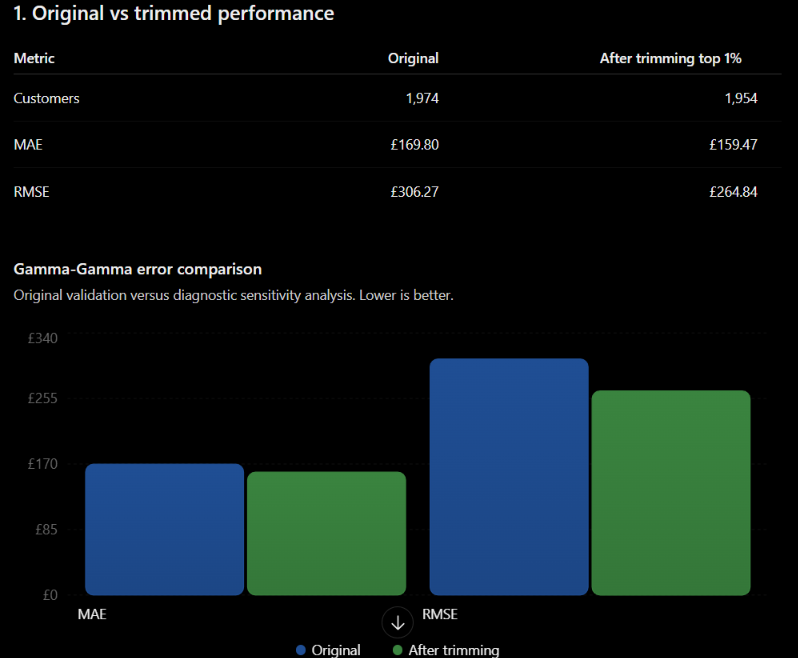

## Combine BG/NBD and Gamma-Gamma validation

In [62]:
# Merge frequency and monetary predictions

clv_validation = validation_comparison[
    ['Customer ID', 'PredictedPurchases_90D']
].merge(
    calibration_monetary[
        ['Customer ID', 'PredictedOrderValue']
    ],
    on='Customer ID',
    how='inner'
)

# Calculate predicted 90-day CLV

clv_validation['PredictedCLV_90D'] = (
    clv_validation['PredictedPurchases_90D'] *
    clv_validation['PredictedOrderValue']
)

print("Customers with CLV predictions:", len(clv_validation))

print(
    "Total predicted 90-day revenue:",
    round(clv_validation['PredictedCLV_90D'].sum(), 2)
)

display(clv_validation.head(10))

Customers with CLV predictions: 3705
Total predicted 90-day revenue: 1817231.63


,Customer ID,PredictedPurchases_90D,PredictedOrderValue,PredictedCLV_90D
0,12346.0,0.550829,6557.774056,3612.210637
1,12347.0,1.369664,584.521609,800.598122
2,12348.0,0.661919,447.621332,296.288944
3,12349.0,0.244716,946.119459,231.530897
4,12352.0,0.561564,279.667926,157.051362
5,12353.0,0.380279,224.660510,85.433594
6,12355.0,0.286105,520.657440,148.962534
7,12356.0,0.793131,1308.647566,1037.928707
8,12357.0,0.067177,6613.197511,444.255633
9,12358.0,0.502345,838.106329,421.018123


### Actual vs Predicted CLV

In [63]:
# Get all calibration customers
calibration_customers = calibration_monetary[
    ['Customer ID']
].drop_duplicates()

# Merge actual validation revenue
clv_validation = clv_validation.merge(
    actual_monetary[
        ['Customer ID', 'ActualRevenue']
    ],
    on='Customer ID',
    how='left'
)

# Customers with no purchases during validation get zero revenue
clv_validation['ActualRevenue'] = (
    clv_validation['ActualRevenue'].fillna(0)
)

# Compare predicted and actual CLV
clv_validation['CLV_Error'] = (
    clv_validation['PredictedCLV_90D'] -
    clv_validation['ActualRevenue']
)

clv_validation['AbsoluteError'] = (
    clv_validation['CLV_Error'].abs()
)

print("Customers evaluated:", len(clv_validation))
print(
    "Total predicted revenue:",
    round(clv_validation['PredictedCLV_90D'].sum(), 2)
)
print(
    "Total actual revenue:",
    round(clv_validation['ActualRevenue'].sum(), 2)
)
print(
    "Total absolute error:",
    round(clv_validation['AbsoluteError'].sum(), 2)
)

display(clv_validation.head(10))

Customers evaluated: 3705
Total predicted revenue: 1817231.63
Total actual revenue: 2711989.17
Total absolute error: 1887864.11


,Customer ID,PredictedPurchases_90D,PredictedOrderValue,PredictedCLV_90D,ActualRevenue,CLV_Error,AbsoluteError
0,12346.0,0.550829,6557.774056,3612.210637,0.00,3612.210637,3612.210637
1,12347.0,1.369664,584.521609,800.598122,1519.14,-718.541878,718.541878
2,12348.0,0.661919,447.621332,296.288944,310.00,-13.711056,13.711056
3,12349.0,0.244716,946.119459,231.530897,1757.55,-1526.019103,1526.019103
4,12352.0,0.561564,279.667926,157.051362,944.23,-787.178638,787.178638
5,12353.0,0.380279,224.660510,85.433594,0.00,85.433594,85.433594
6,12355.0,0.286105,520.657440,148.962534,0.00,148.962534,148.962534
7,12356.0,0.793131,1308.647566,1037.928707,58.35,979.578707,979.578707
8,12357.0,0.067177,6613.197511,444.255633,6207.67,-5763.414367,5763.414367
9,12358.0,0.502345,838.106329,421.018123,683.20,-262.181877,262.181877


## Final Validation metrics

In [64]:
import numpy as np

y_actual = clv_validation['ActualRevenue']
y_predicted = clv_validation['PredictedCLV_90D']

mae = np.mean(np.abs(y_actual - y_predicted))
rmse = np.sqrt(np.mean((y_actual - y_predicted) ** 2))
bias = np.mean(y_predicted - y_actual)

wape = (
    np.sum(np.abs(y_actual - y_predicted)) /
    np.sum(y_actual)
) * 100

actual_total = y_actual.sum()
predicted_total = y_predicted.sum()

underprediction = (
    (actual_total - predicted_total) / actual_total
) * 100

print("FINAL CLV VALIDATION")
print("-" * 40)
print(f"MAE: £{mae:,.2f}")
print(f"RMSE: £{rmse:,.2f}")
print(f"Mean Bias: £{bias:,.2f}")
print(f"WAPE: {wape:.2f}%")
print(f"Aggregate Underprediction: {underprediction:.2f}%")

FINAL CLV VALIDATION
----------------------------------------
MAE: £509.54
RMSE: £2,525.59
Mean Bias: £-241.50
WAPE: 69.61%
Aggregate Underprediction: 32.99%


# CLV Model Validation — 90-Day Holdout Evaluation

## 1. Validation Overview

The BG/NBD and Gamma-Gamma models were evaluated using a time-based validation approach.

- **Calibration period:** Historical transactions before September 10, 2011.
- **Validation period:** The subsequent 90-day period, ending December 9, 2011.
- **Evaluation cohort:** 3,705 repeat customers identified during the calibration period.

The objective was to compare predicted 90-day customer lifetime value against actual revenue generated during the validation period.

## 2. BG/NBD Model Validation

The BG/NBD model estimated the expected number of purchases over the next 90 days.

| Metric | Result |
|---|---:|
| Calibration customers | 5,281 |
| Repeat customers | 3,705 |
| Predicted purchases | 3,891.23 |
| Actual purchases | 5,081 |
| Mean Absolute Error (MAE) | 0.9465 |
| Root Mean Squared Error (RMSE) | 1.9117 |
| Mean Bias | -0.3211 |
| Aggregate underprediction | 23.42% |

The model systematically underestimated purchase frequency, particularly among highly active customers.

## 3. Gamma-Gamma Model Validation

The Gamma-Gamma model estimated the average monetary value per purchase.

The evaluation included 1,974 calibration customers who made purchases during the validation period.

| Metric | Result |
|---|---:|
| Customers evaluated | 1,974 |
| Average predicted order value | £414.41 |
| Average actual order value | £436.35 |
| MAE | £169.80 |
| RMSE | £306.27 |
| Mean Bias | -£21.94 |
| MAPE | 63.62% |

The model produced a reasonably close aggregate average order value, but individual customer-level predictions showed substantial variation.

**Outlier sensitivity analysis:**

After excluding the top 1% of actual validation order values for diagnostic purposes:

- Original MAE: £169.80
- Adjusted MAE: £159.47
- Original RMSE: £306.27
- Adjusted RMSE: £264.84

This analysis indicates that extreme transactions contribute to prediction errors, although they do not explain all the errors.

The excluded observations were retained in the original dataset and model evaluation.

## 4. Combined 90-Day CLV Validation

Predicted CLV was calculated using:

`Predicted CLV = Predicted Purchases × Predicted Average Order Value`

The predictions were compared against actual revenue generated by the same customers during the 90-day validation period.

Customers who did not make purchases during validation were assigned zero actual revenue.

### Overall Results

| Metric | Result |
|---|---:|
| Customers evaluated | 3,705 |
| Total predicted 90-day revenue | £1,817,231.63 |
| Total actual 90-day revenue | £2,711,989.17 |
| MAE | £509.54 |
| RMSE | £2,525.59 |
| Mean Bias | -£241.50 |
| WAPE | 69.61% |
| Aggregate underprediction | 32.99% |

### Key Findings

1. **Systematic underprediction:** The model predicted approximately 33% less revenue than the actual revenue generated by the evaluation cohort.
2. **High individual-level error:** WAPE of 69.61% indicates substantial prediction errors relative to actual revenue.
3. **Influence of high-value customers:** RMSE is considerably higher than MAE, suggesting that some customers have particularly large prediction errors.
4. **Aggregate versus individual performance:** The model provides an exploratory estimate of aggregate customer value, but individual customer predictions require improvement.

## 5. Limitations

- The evaluation uses a single 90-day holdout period.
- BG/NBD systematically underestimated purchase frequency.
- Gamma-Gamma individual monetary predictions showed considerable variation.
- Extreme customer spending patterns influenced prediction errors.
- The model estimates revenue, not net profit.
- New customers acquired during the validation period were not included in the calibration customer cohort.
- The dataset represents historical retail transactions and may not generalise to other industries.

## 6. Conclusion

The combined BG/NBD and Gamma-Gamma approach successfully established a predictive CLV estimation pipeline.

However, the validation results demonstrate that the current implementation has limited individual-level predictive accuracy. The 69.61% WAPE and 32.99% aggregate underprediction highlight the need for further calibration, feature development, and validation across multiple time periods.

The model will therefore be presented as an **exploratory customer-value estimation baseline**, rather than a production-ready revenue forecasting system.

The results can still support customer prioritisation, segmentation, and retention strategy exploration when interpreted alongside the model's limitations.